<a href="https://colab.research.google.com/github/trsantanarural/predicao-falhas-tarefas/blob/main/notebooks/04_agrupamento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04. Agrupamento: K-Means e DBSCAN

**Entrada:** `saida/base_modelagem.parquet` (notebook 02)
**Saídas:** `saida/base_conjuntos.parquet` (conjunto de cada tarefa, usado também no notebook 05), `saida/agrupamento_*.csv` e figuras em `figuras/`

Este notebook:
1. atribui cada job por inteiro a um conjunto (treino, validação ou teste), pelo dia da sua primeira tarefa;
2. prepara as métricas de consumo (imputação, `log(1 + x)` e padronização, ajustadas só no treino);
3. ajusta o K-Means e o DBSCAN no treino (dias 1 a 19), sem o rótulo;
4. associa as tarefas de validação e de teste aos grupos e avalia o escore de atipicidade (distância ao centroide ou ao ponto central mais próximo) por ROC-AUC e PR-AUC, além da proporção de falhas por grupo.

Os critérios de escolha de `minPts` e de ε estão fixados antes de olhar o resultado: `minPts` = 2 × número de atributos e ε no cotovelo da curva de distâncias ao k-ésimo vizinho (ponto de maior afastamento em relação à reta que liga as extremidades da curva).

## 1. Configuração do ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, roc_auc_score, average_precision_score

# Pasta de trabalho no Google Drive (base do notebook 02, saídas e figuras)
BASE = '/content/drive/MyDrive/artigo_predicao'
FIG = f'{BASE}/figuras'
SAIDA = f'{BASE}/saida'
os.makedirs(FIG, exist_ok=True)

SEED = 42
KEY = ['job_id', 'task_index']

# Métricas de consumo usadas no agrupamento (sem tempo_obs e n_janelas, que carregam a duração)
CONSUMO = ['cpu_rate', 'canonical_mem', 'assigned_mem', 'unmapped_cache', 'total_cache',
           'disk_space', 'cpi', 'mai', 'sampled_cpu', 'max_mem', 'max_cpu']
NOMES = {'cpu_rate': 'CPU média', 'canonical_mem': 'Memória canônica', 'assigned_mem': 'Memória atribuída',
         'unmapped_cache': 'Cache não mapeado', 'total_cache': 'Cache total', 'disk_space': 'Espaço em disco',
         'cpi': 'Ciclos por instrução', 'mai': 'Acessos à memória por instrução',
         'sampled_cpu': 'Amostra de CPU', 'max_mem': 'Memória máxima', 'max_cpu': 'CPU máxima'}

AZUL, LARANJA = '#2a78d6', '#eb6834'
TXT, TXT2, GRADE = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'font.size': 10, 'axes.edgecolor': TXT2, 'axes.labelcolor': TXT, 'xtick.color': TXT2,
    'ytick.color': TXT2, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.bbox': 'tight'})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Divisão por job
Cada job vai por inteiro para o conjunto do dia da sua primeira tarefa (menor `dia` entre as tarefas do job na base): dias 1 a 19 no treino, 20 a 23 na validação e 24 a 29 no teste. Isso elimina a sobreposição de jobs entre os conjuntos (na divisão por dia da tarefa, usada na análise exploratória, 9 jobs ficavam em mais de um conjunto).

In [2]:
base = pd.read_parquet(f'{SAIDA}/base_modelagem.parquet')

dia_job = base.groupby('job_id').dia.min().rename('dia_job')
base = base.join(dia_job, on='job_id')
base['conjunto'] = np.select([base.dia_job >= 24, base.dia_job >= 20], ['teste', 'validação'], 'treino')

# Comparação com a divisão por dia da tarefa
por_tarefa = np.select([base.dia >= 24, base.dia >= 20], ['teste', 'validação'], 'treino')
print('tarefas que mudam de conjunto em relação à divisão por dia da tarefa:', int((por_tarefa != base.conjunto).sum()))

resumo = base.groupby('conjunto').falha.agg(tarefas='size', falhas='sum', taxa='mean')
resumo['jobs'] = base.groupby('conjunto').job_id.nunique()
print(resumo.reindex(['treino', 'validação', 'teste']).round(4).to_string())

base[KEY + ['dia', 'dia_job', 'conjunto', 'falha']].to_parquet(f'{SAIDA}/base_conjuntos.parquet', index=False)

tarefas que mudam de conjunto em relação à divisão por dia da tarefa: 10110
           tarefas  falhas    taxa  jobs
conjunto                                
treino      485308   30164  0.0622  5415
validação   104308    6823  0.0654  1282
teste       134733    9058  0.0672  1697


## 3. Preparação das métricas de consumo
Os valores ausentes de CPI e MAI são imputados pela mediana do treino; em seguida aplica-se `log(1 + x)` e a padronização com média e desvio padrão do treino. O peso de cada tarefa é o inverso do número de tarefas do seu job na base.

In [3]:
tr = base[base.conjunto == 'treino'].copy()

medianas = tr[CONSUMO].median()                      # mediana do treino (imputação)
def prepara(df):
    x = df[CONSUMO].fillna(medianas)
    return np.log1p(x.to_numpy(dtype='float64'))

escala = StandardScaler().fit(prepara(tr))
def padroniza(df):
    return escala.transform(prepara(df))

n_job = base.groupby('job_id').size()
base['peso'] = 1.0 / base.job_id.map(n_job)
tr = base[base.conjunto == 'treino'].copy()
X_tr = padroniza(tr)
print('treino:', X_tr.shape, '| jobs:', tr.job_id.nunique())

treino: (485308, 11) | jobs: 5415


## 4. Amostra do treino com limite de tarefas por job
O DBSCAN tem custo quadrático nas vizinhanças e, sem limite, os poucos jobs com milhares de tarefas quase idênticas formariam os grupos densos. Cada job contribui com no máximo `LIMITE` tarefas (amostra aleatória, semente fixa). O limite é o primeiro de 50, 20, 10 e 5 que deixa a amostra com até 100.000 pontos.

In [4]:
MAX_PONTOS = 100_000
embaralhada = tr.sample(frac=1.0, random_state=SEED)
for LIMITE in (50, 20, 10, 5):
    amostra = embaralhada[embaralhada.groupby('job_id').cumcount() < LIMITE]
    print(f'limite {LIMITE:>2} tarefas por job -> {len(amostra):,} pontos'.replace(',', '.'))
    if len(amostra) <= MAX_PONTOS:
        break
print('LIMITE adotado:', LIMITE, '| pontos:', len(amostra), '| taxa de falha na amostra:', round(amostra.falha.mean(), 4))
X_am = padroniza(amostra)

limite 50 tarefas por job -> 60.560 pontos
LIMITE adotado: 50 | pontos: 60560 | taxa de falha na amostra: 0.0395


## 5. K-Means
Ajustado nas tarefas de treino com peso por job, para k de 2 a 10. A silhueta média é calculada em uma subamostra de até 20.000 pontos da amostra limitada por job (o custo é quadrático). O k adotado é o de maior silhueta; o gráfico do cotovelo (inércia ponderada) acompanha a escolha. Se, olhando os dois gráficos, outro k for preferível, defina `K_ESCOLHIDO` manualmente e justifique no artigo.

k =  2 | inércia ponderada = 38 163.2 | silhueta = 0.6813
k =  3 | inércia ponderada = 27 425.5 | silhueta = 0.5186
k =  4 | inércia ponderada = 23 550.9 | silhueta = 0.3913
k =  5 | inércia ponderada = 20 528.3 | silhueta = 0.3698
k =  6 | inércia ponderada = 18 139.5 | silhueta = 0.3833
k =  7 | inércia ponderada = 16 378.8 | silhueta = 0.3897
k =  8 | inércia ponderada = 14 935.1 | silhueta = 0.3912
k =  9 | inércia ponderada = 13 495.1 | silhueta = 0.3263
k = 10 | inércia ponderada = 12 491.6 | silhueta = 0.3513


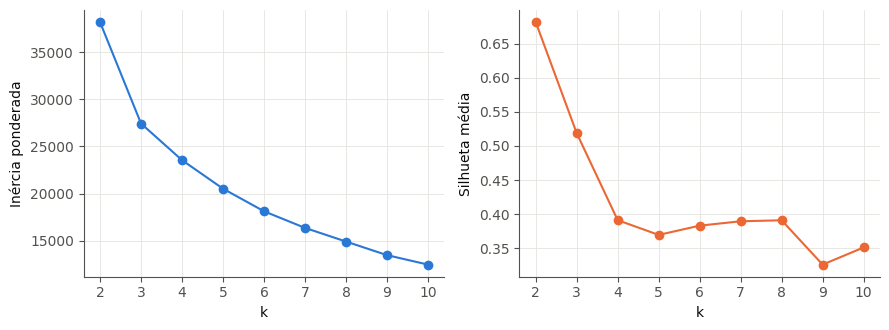

In [5]:
rng = np.random.RandomState(SEED)
idx_sil = rng.choice(len(X_am), size=min(20_000, len(X_am)), replace=False)

ks = list(range(2, 11))
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X_tr, sample_weight=tr.peso.to_numpy())
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_am[idx_sil], km.predict(X_am[idx_sil])))
    print(f'k = {k:>2} | inércia ponderada = {km.inertia_:,.1f} | silhueta = {silueta[-1]:.4f}'.replace(',', ' '))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].plot(ks, inercia, marker='o', color=AZUL); axs[0].set_xlabel('k'); axs[0].set_ylabel('Inércia ponderada')
axs[1].plot(ks, silueta, marker='o', color=LARANJA); axs[1].set_xlabel('k'); axs[1].set_ylabel('Silhueta média')
for ax in axs: ax.set_xticks(ks)
fig.tight_layout()
fig.savefig(f'{FIG}/kmeans_cotovelo_silhueta.png', dpi=200)
plt.show()

In [6]:
K_ESCOLHIDO = None          # defina um inteiro para substituir a escolha automática
K = K_ESCOLHIDO or ks[int(np.argmax(silueta))]
print('k adotado:', K)

km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_tr, sample_weight=tr.peso.to_numpy())
tr['grupo'] = km.labels_

# Descrição dos grupos no treino: tamanho, taxa de falha e centroide (escala original aproximada)
cent = pd.DataFrame(escala.inverse_transform(km.cluster_centers_), columns=CONSUMO)
cent = np.expm1(cent)
cent.columns = [NOMES[c] for c in CONSUMO]
desc = tr.groupby('grupo').falha.agg(tarefas='size', falhas='sum', taxa='mean').round(4)
desc['jobs'] = tr.groupby('grupo').job_id.nunique()
print(desc.to_string())
print()
print(cent.round(5).T.to_string())

k adotado: 2
       tarefas  falhas    taxa  jobs
grupo                               
0        23924     431  0.0180   306
1       461384   29733  0.0644  5281

                                       0        1
CPU média                        0.06885  0.00822
Memória canônica                 0.03872  0.00243
Memória atribuída                0.04847  0.00427
Cache não mapeado                0.00237  0.00043
Cache total                      0.00962  0.00067
Espaço em disco                  0.00005  0.00000
Ciclos por instrução             1.73331  3.36395
Acessos à memória por instrução  0.00425  0.01490
Amostra de CPU                   0.06987  0.00824
Memória máxima                   0.06079  0.00483
CPU máxima                       0.37405  0.08247


## 6. DBSCAN
`minPts` = 2 × número de atributos. O ε é lido na curva das distâncias ao `minPts`-ésimo vizinho, ordenadas, no ponto de maior afastamento em relação à reta que liga as extremidades da curva.

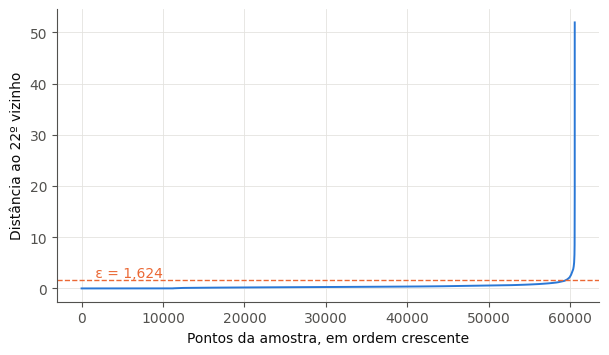

minPts: 22 | ε sugerido pelo cotovelo: 1.6239


In [7]:
MINPTS = 2 * len(CONSUMO)
nn = NearestNeighbors(n_neighbors=MINPTS).fit(X_am)
kdist = np.sort(nn.kneighbors(X_am)[0][:, -1])

# cotovelo: ponto da curva mais distante da reta entre as extremidades
xn = np.arange(len(kdist)) / (len(kdist) - 1)
yn = (kdist - kdist[0]) / (kdist[-1] - kdist[0])
i_joelho = int(np.argmax(xn - yn))
EPS_AUTO = float(kdist[i_joelho])

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(kdist, color=AZUL, lw=1.4)
ax.axhline(EPS_AUTO, ls='--', lw=1, color=LARANJA)
ax.text(len(kdist) * 0.02, EPS_AUTO, f' ε = {EPS_AUTO:.3f}'.replace('.', ','), va='bottom', color=LARANJA)
ax.set_xlabel('Pontos da amostra, em ordem crescente'); ax.set_ylabel(f'Distância ao {MINPTS}º vizinho')
fig.savefig(f'{FIG}/dbscan_kdistance.png', dpi=200)
plt.show()
print('minPts:', MINPTS, '| ε sugerido pelo cotovelo:', round(EPS_AUTO, 4))

In [8]:
EPS_ESCOLHIDO = 1.0        # defina um número para substituir o valor do cotovelo
EPS = EPS_ESCOLHIDO or EPS_AUTO
print('ε adotado:', round(EPS, 4))

# Verificação de memória: o DBSCAN guarda a vizinhança de cada ponto (n x tamanho médio da vizinhança).
sond = np.random.RandomState(SEED).choice(len(X_am), size=min(500, len(X_am)), replace=False)
viz = NearestNeighbors(radius=EPS).fit(X_am).radius_neighbors(X_am[sond], return_distance=False)
media_viz = float(np.mean([len(v) for v in viz]))
mem_gb = len(X_am) * media_viz * 8 / 1e9
print(f'vizinhos médios dentro de ε: {media_viz:.0f} | memória estimada das vizinhanças: {mem_gb:.1f} GB')
if mem_gb > 4:
    raise RuntimeError('ε grande demais para a amostra: o DBSCAN ficaria sem memória. '
                       'Reduza MAX_PONTOS (seção 4) ou defina EPS_ESCOLHIDO e justifique no artigo.')

db = DBSCAN(eps=EPS, min_samples=MINPTS, n_jobs=-1).fit(X_am)
amostra = amostra.assign(grupo_db=db.labels_)
n_grupos = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print('grupos:', n_grupos, '| pontos centrais:', len(db.core_sample_indices_),
      '| ruído (%):', round((db.labels_ == -1).mean() * 100, 1))

d = amostra.groupby('grupo_db').falha.agg(tarefas='size', falhas='sum', taxa='mean').round(4)
d['jobs'] = amostra.groupby('grupo_db').job_id.nunique()
print(d.rename(index={-1: 'ruído'}).to_string())

ε adotado: 1.0
vizinhos médios dentro de ε: 7414 | memória estimada das vizinhanças: 3.6 GB
grupos: 27 | pontos centrais: 57397 | ruído (%): 2.8
          tarefas  falhas    taxa  jobs
grupo_db                               
ruído        1692     244  0.1442   432
0           56103    2128  0.0379  5185
1             134       0  0.0000     3
2             440       0  0.0000    16
3              56       3  0.0536     3
4              84       5  0.0595     9
5             525       9  0.0171    11
6              33       0  0.0000     1
7             105       0  0.0000     4
8             362       0  0.0000     9
9              50       0  0.0000     1
10             99       3  0.0303     2
11             97       2  0.0206     2
12             34       0  0.0000     1
13             80       0  0.0000     3
14             24       0  0.0000     2
15             46       0  0.0000     1
16            152       0  0.0000     6
17             50       0  0.0000     5
18             

## 7. Associação das tarefas de validação e de teste e avaliação
- **K-Means:** cada tarefa vai ao centroide mais próximo; o escore de atipicidade é a distância a ele.
- **DBSCAN:** o algoritmo não atribui observações novas; cada tarefa é associada ao ponto central mais próximo, se ele estiver a menos de ε, e rotulada como ruído caso contrário. O escore de atipicidade é a distância ao ponto central mais próximo.

ROC-AUC e PR-AUC avaliam se o escore ordena as tarefas com falha acima das concluídas, sem uso do rótulo no ajuste. A PR-AUC de um escore sem informação é igual à taxa de falha do conjunto. As métricas aparecem também sem o job com mais falhas do conjunto, que no teste concentra a maior parte delas.

In [9]:
# Pontos centrais do DBSCAN e seus rótulos
centrais = db.components_
rot_centrais = db.labels_[db.core_sample_indices_]
nn_c = NearestNeighbors(n_neighbors=1).fit(centrais)

def aplica(df):
    X = padroniza(df)
    d_km = km.transform(X)
    g_km, s_km = d_km.argmin(axis=1), d_km.min(axis=1)
    dist, pos = nn_c.kneighbors(X)
    dist, pos = dist[:, 0], pos[:, 0]
    g_db = np.where(dist < EPS, rot_centrais[pos], -1)
    return g_km, s_km, g_db, dist

def metricas(y, s):
    return roc_auc_score(y, s), average_precision_score(y, s)

linhas, grupos_tab = [], []
for conj in ('validação', 'teste'):
    df = base[base.conjunto == conj].copy()
    g_km, s_km, g_db, s_db = aplica(df)
    df['grupo_km'], df['esc_km'], df['grupo_db'], df['esc_db'] = g_km, s_km, g_db, s_db

    # job com mais falhas do conjunto
    top = df[df.falha == 1].groupby('job_id').size().idxmax()
    for rotulo, sub in (('todos os jobs', df), (f'sem o job {top}', df[df.job_id != top])):
        for nome, col in (('K-Means', 'esc_km'), ('DBSCAN', 'esc_db')):
            roc, pr = metricas(sub.falha, sub[col])
            linhas.append({'conjunto': conj, 'recorte': rotulo, 'método': nome, 'tarefas': len(sub),
                           'taxa de falha': round(sub.falha.mean(), 4),
                           'ROC-AUC': round(roc, 4), 'PR-AUC': round(pr, 4)})
        ruido = sub[sub.grupo_db == -1]
        linhas.append({'conjunto': conj, 'recorte': rotulo, 'método': 'DBSCAN: pontos de ruído',
                       'tarefas': len(ruido), 'taxa de falha': round(ruido.falha.mean(), 4) if len(ruido) else np.nan,
                       'ROC-AUC': np.nan, 'PR-AUC': np.nan})

    for nome, col in (('K-Means', 'grupo_km'), ('DBSCAN', 'grupo_db')):
        t = df.groupby(col).falha.agg(tarefas='size', falhas='sum', taxa='mean').round(4).reset_index()
        t.insert(0, 'método', nome); t.insert(0, 'conjunto', conj); t = t.rename(columns={col: 'grupo'})
        grupos_tab.append(t)

res = pd.DataFrame(linhas)
print(res.to_string(index=False))

 conjunto              recorte                  método  tarefas  taxa de falha  ROC-AUC  PR-AUC
validação        todos os jobs                 K-Means   104308         0.0654   0.6787  0.1086
validação        todos os jobs                  DBSCAN   104308         0.0654   0.6986  0.2312
validação        todos os jobs DBSCAN: pontos de ruído     7005         0.4551      NaN     NaN
validação sem o job 6418746280                 K-Means   101193         0.0366   0.5076  0.0344
validação sem o job 6418746280                  DBSCAN   101193         0.0366   0.4676  0.0342
validação sem o job 6418746280 DBSCAN: pontos de ruído     4029         0.0526      NaN     NaN
    teste        todos os jobs                 K-Means   134733         0.0672   0.3705  0.0483
    teste        todos os jobs                  DBSCAN   134733         0.0672   0.4960  0.0601
    teste        todos os jobs DBSCAN: pontos de ruído    25115         0.0239      NaN     NaN
    teste sem o job 6449919400          

In [10]:
grupos_tab = pd.concat(grupos_tab, ignore_index=True)
grupos_tab['grupo'] = grupos_tab.grupo.astype(str).replace({'-1': 'ruído'})
print(grupos_tab.to_string(index=False))

 conjunto  método grupo  tarefas  falhas   taxa
validação K-Means     0     9359    3051 0.3260
validação K-Means     1    94949    3772 0.0397
validação  DBSCAN ruído     7005    3188 0.4551
validação  DBSCAN     0    94871    3526 0.0372
validação  DBSCAN     2       53       0 0.0000
validação  DBSCAN     3     1045      44 0.0421
validação  DBSCAN     4       70      61 0.8714
validação  DBSCAN     7       23       0 0.0000
validação  DBSCAN     8     1038       0 0.0000
validação  DBSCAN    15       45       0 0.0000
validação  DBSCAN    16       46       0 0.0000
validação  DBSCAN    17        1       0 0.0000
validação  DBSCAN    18       64       0 0.0000
validação  DBSCAN    19       32       0 0.0000
validação  DBSCAN    20        1       0 0.0000
validação  DBSCAN    21        4       4 1.0000
validação  DBSCAN    24        9       0 0.0000
validação  DBSCAN    26        1       0 0.0000
    teste K-Means     0    19013     559 0.0294
    teste K-Means     1   115720    8499

## 8. Gravação dos resultados

In [11]:
res.to_csv(f'{SAIDA}/agrupamento_metricas.csv', index=False)
grupos_tab.to_csv(f'{SAIDA}/agrupamento_grupos.csv', index=False)
pd.DataFrame({'parametro': ['k', 'limite_por_job', 'pontos_amostra', 'minPts', 'eps'],
              'valor': [K, LIMITE, len(amostra), MINPTS, EPS]}).to_csv(f'{SAIDA}/agrupamento_parametros.csv', index=False)
print('gravado em', SAIDA)

gravado em /content/drive/MyDrive/artigo_predicao/saida


## 9. Figuras do agrupamento
Execute depois das seções anteriores, na mesma sessão. Esta seção regrava `kmeans_cotovelo_silhueta.png` (cotovelo de k = 1 a 10 e silhueta média, com o k adotado marcado) e `dbscan_kdistance.png` (escala logarítmica, com o ε adotado e o ε do cotovelo) e cria `kmeans_silhueta_grupos.png` (silhueta por grupo para k = 2, 3 e 4, ao lado da projeção PCA) e `agrupamento_pca.png` (classe, K-Means e DBSCAN na mesma projeção). Em todas as figuras os grupos do K-Means são numerados do maior para o menor CPU média do centroide. A projeção PCA serve só para visualização; os grupos foram formados nas 11 dimensões.

variância explicada: componente 1 = 49,4% | componente 2 = 15,4% | soma = 64,8%
rótulos do K-Means final coincidem com a numeração das figuras: True


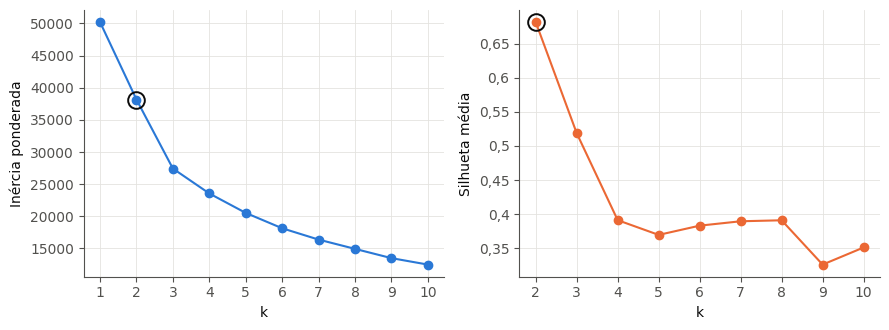

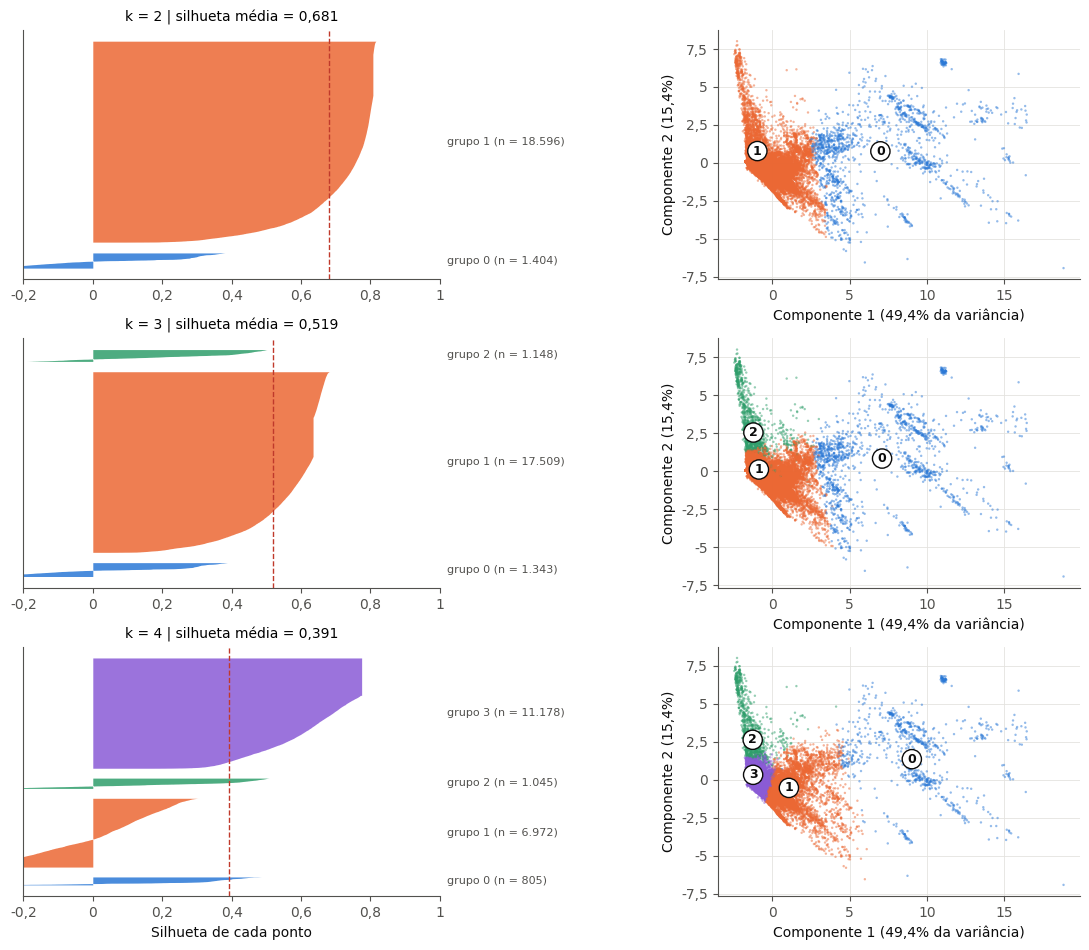

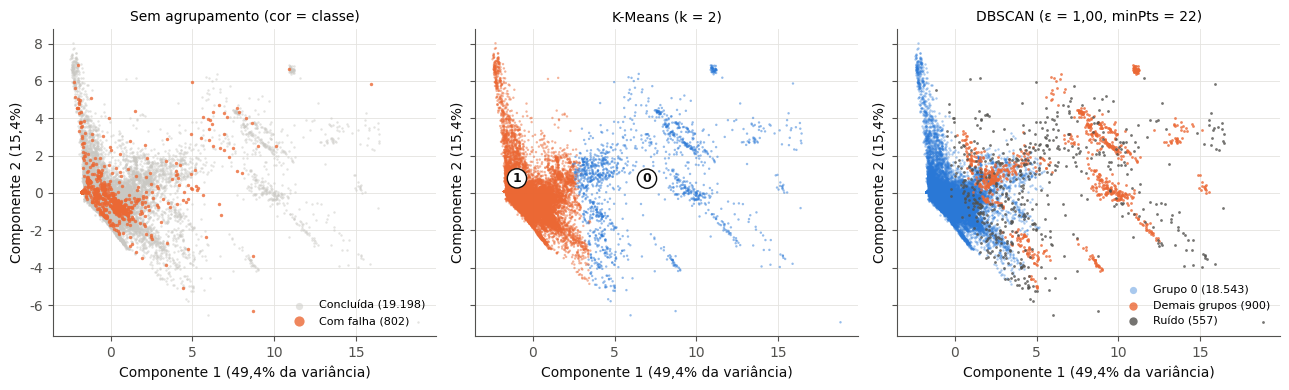

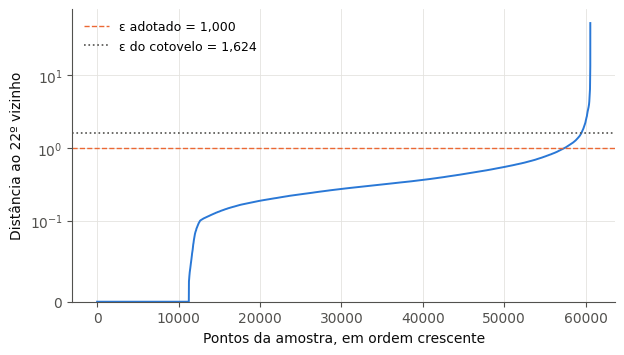

In [12]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FuncFormatter

CORES = [AZUL, LARANJA, '#2f9e6b', '#8a5bd6', '#c2a21f', '#d6457a']
CINZA = '#9a9a96'
ZOOM = False        # True recorta as dispersões entre os percentis 0,5 e 99,5 (a legenda informa quantos pontos ficam fora)

FMT = FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))     # vírgula decimal nos eixos
def pt(v): return f'{v:,.0f}'.replace(',', '.')
def vir(x, n=2): return f'{x:.{n}f}'.replace('.', ',')

# PCA ajustada na amostra do DBSCAN; a mesma projeção vale para todas as dispersões
pca = PCA(n_components=2, random_state=SEED).fit(X_am)
Z = pca.transform(X_am[idx_sil])
var = pca.explained_variance_ratio_ * 100
print(f'variância explicada: componente 1 = {vir(var[0], 1)}% | componente 2 = {vir(var[1], 1)}% | soma = {vir(var.sum(), 1)}%')
y_z = amostra.falha.to_numpy()[idx_sil]
lab_db = db.labels_[idx_sil]

# Numeração dos grupos igual em todas as figuras: do maior para o menor CPU média do centroide.
# (Os rótulos de ajustes diferentes do K-Means são arbitrários; sem isso, o grupo 0 de uma figura pode ser o grupo 1 de outra.)
cpu_i = CONSUMO.index('cpu_rate')
def renumera(modelo, lab):
    cpu = np.expm1(escala.inverse_transform(modelo.cluster_centers_))[:, cpu_i]
    ordem = np.argsort(-cpu)                          # ordem[novo] = rótulo original
    novo = np.empty(len(ordem), dtype=int); novo[ordem] = np.arange(len(ordem))
    return novo[lab], modelo.cluster_centers_[ordem]
lab_K, cent_K = renumera(km, km.predict(X_am[idx_sil]))
_, cent_ref = renumera(km, np.array([0]))
print('rótulos do K-Means final coincidem com a numeração das figuras:', bool(np.allclose(cent_ref, km.cluster_centers_)))
if ZOOM:
    lo, hi = np.percentile(Z, 0.5, axis=0), np.percentile(Z, 99.5, axis=0)
    fora = ((Z < lo) | (Z > hi)).any(axis=1).mean() * 100
    print(f'ZOOM ligado: {vir(fora, 1)}% dos pontos ficam fora da janela')

def eixos_pca(ax):
    ax.set_xlabel(f'Componente 1 ({vir(var[0], 1)}% da variância)')
    ax.set_ylabel(f'Componente 2 ({vir(var[1], 1)}%)')
    ax.xaxis.set_major_formatter(FMT); ax.yaxis.set_major_formatter(FMT)
    if ZOOM:
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])

def centroides(ax, centros):
    c = pca.transform(centros)
    for g, (a, b) in enumerate(c):
        ax.text(a, b, str(g), ha='center', va='center', fontsize=9, fontweight='bold', color=TXT,
                bbox=dict(boxstyle='circle,pad=0.25', fc='white', ec=TXT, lw=1), zorder=5)

# --- Figura A: cotovelo (k = 1 a 10) e silhueta média ---
w = tr.peso.to_numpy()
mu = np.average(X_tr, axis=0, weights=w)
inercia_1 = float((w * ((X_tr - mu) ** 2).sum(axis=1)).sum())
ks1, in1 = [1] + list(ks), [inercia_1] + list(inercia)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].plot(ks1, in1, marker='o', color=AZUL)
axs[0].plot(K, in1[ks1.index(K)], 'o', ms=12, mfc='none', mec=TXT, mew=1.4)
axs[0].set_xlabel('k'); axs[0].set_ylabel('Inércia ponderada'); axs[0].set_xticks(ks1)
axs[1].plot(ks, silueta, marker='o', color=LARANJA)
axs[1].plot(K, silueta[ks.index(K)], 'o', ms=12, mfc='none', mec=TXT, mew=1.4)
axs[1].set_xlabel('k'); axs[1].set_ylabel('Silhueta média'); axs[1].set_xticks(ks); axs[1].yaxis.set_major_formatter(FMT)
fig.tight_layout()
fig.savefig(f'{FIG}/kmeans_cotovelo_silhueta.png', dpi=200)
plt.show()

# --- Figura B: silhueta por grupo (esquerda) e grupos na projeção PCA (direita), para k = 2, 3 e 4 ---
KS_DIAG = (2, 3, 4)
fig, axs = plt.subplots(len(KS_DIAG), 2, figsize=(11, 3.2 * len(KS_DIAG)), gridspec_kw={'width_ratios': [1.15, 1]})
for r, kk in enumerate(KS_DIAG):
    mk = KMeans(n_clusters=kk, n_init=3, random_state=SEED).fit(X_tr, sample_weight=w)
    lab, cent = renumera(mk, mk.predict(X_am[idx_sil]))
    sv = silhouette_samples(X_am[idx_sil], lab)
    ax = axs[r, 0]
    folga = 0.05 * len(sv)
    y0 = 0
    for g in range(kk):
        s = np.sort(sv[lab == g])
        ax.fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, color=CORES[g], alpha=0.85, lw=0)
        ax.text(1.02, y0 + len(s) / 2, f'grupo {g} (n = {pt(len(s))})', ha='left', va='center', fontsize=8, color=TXT2)
        y0 += len(s) + folga
    ax.axvline(sv.mean(), color='#c0392b', ls='--', lw=1)
    ax.set_xlim(-0.2, 1.0); ax.set_xticks([-0.2, 0, 0.2, 0.4, 0.6, 0.8, 1.0]); ax.xaxis.set_major_formatter(FMT)
    ax.set_yticks([]); ax.grid(False)
    ax.set_title(f'k = {kk} | silhueta média = {vir(sv.mean(), 3)}', fontsize=10)
    ax.set_xlabel('Silhueta de cada ponto' if r == len(KS_DIAG) - 1 else '')
    ax = axs[r, 1]
    ax.scatter(Z[:, 0], Z[:, 1], c=np.array(CORES)[lab], s=3, alpha=0.5, lw=0)
    centroides(ax, cent)
    eixos_pca(ax)
fig.tight_layout(w_pad=7)
fig.savefig(f'{FIG}/kmeans_silhueta_grupos.png', dpi=200)
plt.show()

# --- Figura C: sem agrupamento (classe) e dados agrupados (K-Means e DBSCAN) ---
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
ax = axs[0]
ax.scatter(Z[y_z == 0, 0], Z[y_z == 0, 1], c='#c9c8c3', s=3, alpha=0.5, lw=0, label=f'Concluída ({pt((y_z == 0).sum())})')
ax.scatter(Z[y_z == 1, 0], Z[y_z == 1, 1], c=LARANJA, s=6, alpha=0.8, lw=0, label=f'Com falha ({pt((y_z == 1).sum())})')
ax.set_title('Sem agrupamento (cor = classe)', fontsize=10); ax.legend(frameon=False, fontsize=8, markerscale=3)

ax = axs[1]
ax.scatter(Z[:, 0], Z[:, 1], c=np.array(CORES)[lab_K], s=3, alpha=0.5, lw=0)
centroides(ax, cent_K)
ax.set_title(f'K-Means (k = {K})', fontsize=10)

ax = axs[2]
cont = pd.Series(db.labels_[db.labels_ >= 0]).value_counts()
principal = int(cont.idxmax())
m_ru, m_pr = lab_db == -1, lab_db == principal
m_ou = ~(m_ru | m_pr)
ax.scatter(Z[m_pr, 0], Z[m_pr, 1], c=AZUL, s=3, alpha=0.4, lw=0, label=f'Grupo {principal} ({pt(m_pr.sum())})')
ax.scatter(Z[m_ou, 0], Z[m_ou, 1], c=LARANJA, s=4, alpha=0.8, lw=0, label=f'Demais grupos ({pt(m_ou.sum())})')
ax.scatter(Z[m_ru, 0], Z[m_ru, 1], c=TXT2, s=4, alpha=0.8, lw=0, label=f'Ruído ({pt(m_ru.sum())})')
ax.set_title(f'DBSCAN (ε = {vir(EPS)}, minPts = {MINPTS})', fontsize=10); ax.legend(frameon=False, fontsize=8, markerscale=3)
for ax in axs: eixos_pca(ax)
fig.tight_layout()
fig.savefig(f'{FIG}/agrupamento_pca.png', dpi=200)
plt.show()

# --- Figura D: curva de k-distância em escala logarítmica (linear abaixo de 0,1), com ε adotado e ε do cotovelo ---
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(kdist, color=AZUL, lw=1.4)
ax.set_yscale('symlog', linthresh=0.1); ax.set_ylim(bottom=0)
ax.axhline(EPS, ls='--', lw=1, color=LARANJA, label=f'ε adotado = {vir(EPS, 3)}')
if abs(EPS - EPS_AUTO) > 1e-9:
    ax.axhline(EPS_AUTO, ls=':', lw=1.2, color=TXT2, label=f'ε do cotovelo = {vir(EPS_AUTO, 3)}')
ax.set_xlabel('Pontos da amostra, em ordem crescente'); ax.set_ylabel(f'Distância ao {MINPTS}º vizinho')
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.savefig(f'{FIG}/dbscan_kdistance.png', dpi=200)
plt.show()


## 10. Taxa de falha por grupo
Associa as tarefas de treino, validação e teste aos grupos pela mesma regra (centroide mais próximo no K-Means; ponto central do DBSCAN a menos de ε, ruído caso contrário) e calcula a taxa de falha por grupo, com todos os jobs e sem o job com mais falhas de cada conjunto. Os grupos do DBSCAN diferentes do maior aparecem agregados como "demais grupos". Saída: `saida/agrupamento_falha_por_grupo.csv`.

In [13]:
# Proporção de falhas por grupo em treino, validação e teste, com e sem o job com mais falhas de cada conjunto.
# Treino, validação e teste usam a mesma regra de associação (centroide mais próximo; ponto central do DBSCAN a menos de ε).
principal = int(pd.Series(db.labels_[db.labels_ >= 0]).value_counts().idxmax())

linhas = []
for conj in ('treino', 'validação', 'teste'):
    df = base[base.conjunto == conj].copy()
    g_km, _, g_db, _ = aplica(df)
    df['K-Means'] = g_km.astype(str)
    df['DBSCAN'] = np.where(g_db == -1, 'ruído', np.where(g_db == principal, f'grupo {principal}', 'demais grupos'))
    top = df[df.falha == 1].groupby('job_id').size().idxmax()
    for rec, sub in (('todos os jobs', df), ('sem o job dominante', df[df.job_id != top])):
        for met in ('K-Means', 'DBSCAN'):
            t = sub.groupby(met).falha.agg(tarefas='size', falhas='sum', taxa='mean')
            for g, row in t.iterrows():
                linhas.append({'conjunto': conj, 'recorte': rec, 'job dominante': top, 'método': met, 'grupo': g,
                               'tarefas': int(row.tarefas), 'falhas': int(row.falhas),
                               'taxa de falha (%)': round(row.taxa * 100, 2)})

tab_grupos = pd.DataFrame(linhas)
ordem = ['treino', 'validação', 'teste']
for col, rot in (('taxa de falha (%)', 'Taxa de falha (%) por grupo'), ('tarefas', 'Tarefas por grupo')):
    pv = tab_grupos.pivot_table(index=['método', 'grupo'], columns=['conjunto', 'recorte'], values=col, aggfunc='first')
    print(rot); print(pv.reindex(columns=ordem, level=0).to_string()); print()
print(tab_grupos.groupby(['conjunto', 'recorte'])['job dominante'].first().to_string())
tab_grupos.to_csv(f'{SAIDA}/agrupamento_falha_por_grupo.csv', index=False)


Taxa de falha (%) por grupo
conjunto                           treino                         validação                             teste              
recorte               sem o job dominante todos os jobs sem o job dominante todos os jobs sem o job dominante todos os jobs
método  grupo                                                                                                              
DBSCAN  demais grupos                0.68          0.68                4.32          4.48                1.44          1.44
        grupo 0                      2.38          6.82                3.58          3.72                1.77          8.01
        ruído                        3.57          4.40                5.26         45.51                2.38          2.39
K-Means 0                            1.80          1.80                2.91         32.60                2.94          2.94
        1                            2.30          6.44                3.72          3.97               

## 11. Sensibilidade a k e a ε
Repete a avaliação do escore de atipicidade (ROC-AUC e PR-AUC em validação e teste, com e sem o job com mais falhas de cada conjunto) com outros valores dos parâmetros: k = 3 no K-Means, em comparação com o k adotado, e ε = 0,5, 0,7, 1,3 e o ε do cotovelo no DBSCAN, em comparação com o ε adotado. Para poupar memória, os pontos idênticos da amostra (tarefas sem consumo registrado, com CPI e MAI imputados pela mesma mediana) são reunidos em um ponto com peso igual à multiplicidade; o DBSCAN com pesos tem os mesmos pontos centrais e o mesmo ruído, e a célula confere isso no ε adotado. Cada ε só é executado se a estimativa de memória ficar abaixo de 4 GB. Para k = 3 mostra também a taxa de falha por grupo em treino, validação e teste. Saída: `saida/agrupamento_sensibilidade.csv`.

In [14]:
# Sensibilidade das escolhas: k do K-Means e ε do DBSCAN.
# Mesmo procedimento do notebook (escore = distância ao centroide ou ao ponto central mais próximo),
# com e sem o job com mais falhas de cada conjunto.
K_TESTE = (3,)
EPS_TESTE = (0.5, 0.7, 1.3, round(EPS_AUTO, 4))   # inclui o ε do cotovelo; só roda se a estimativa de memória ficar abaixo do limite
LIM_GB = 4

# Pontos idênticos (tarefas sem consumo registrado, com CPI e MAI imputados pela mesma mediana) são reunidos em um ponto
# com peso igual à multiplicidade. O DBSCAN com sample_weight dá os mesmos pontos centrais, o mesmo ruído e a mesma
# partição dos pontos centrais que o ajuste sobre os pontos repetidos, e as vizinhanças ocupam bem menos memória.
Xu, inv, cnt = np.unique(X_am, axis=0, return_inverse=True, return_counts=True)
inv = inv.ravel()
print(f'pontos distintos na amostra: {pt(len(Xu))} de {pt(len(X_am))}')

def mem_estimada(eps):
    sond = np.random.RandomState(SEED).choice(len(Xu), size=min(500, len(Xu)), replace=False)
    viz = NearestNeighbors(radius=eps).fit(Xu).radius_neighbors(Xu[sond], return_distance=False)
    return len(Xu) * float(np.mean([len(v) for v in viz])) * 8 / 1e9

def ajusta_dbscan(eps):
    return DBSCAN(eps=eps, min_samples=MINPTS, n_jobs=-1).fit(Xu, sample_weight=cnt)

linhas_s = []
def avalia(modelo, conj, df, score, ruido=None):
    top = df[df.falha == 1].groupby('job_id').size().idxmax()
    y = df.falha.to_numpy()
    for rec, m in (('todos os jobs', np.ones(len(df), bool)), ('sem o job dominante', (df.job_id != top).to_numpy())):
        roc, pr = metricas(y[m], score[m])
        linha = {'modelo': modelo, 'conjunto': conj, 'recorte': rec, 'taxa de falha': round(y[m].mean(), 4),
                 'ROC-AUC': round(roc, 4), 'PR-AUC': round(pr, 4)}
        if ruido is not None:
            linha['ruído (%)'] = round(ruido[m].mean() * 100, 1)
            linha['falha no ruído (%)'] = round(y[m][ruido[m]].mean() * 100, 2) if ruido[m].any() else np.nan
        linhas_s.append(linha)

def taxas_km(mk, nome):
    out = []
    for conj in ('treino', 'validação', 'teste'):
        df = base[base.conjunto == conj]
        g, _ = renumera(mk, mk.predict(padroniza(df)))
        top = df[df.falha == 1].groupby('job_id').size().idxmax()
        for rec, m in (('todos os jobs', np.ones(len(df), bool)), ('sem o job dominante', (df.job_id != top).to_numpy())):
            t = pd.DataFrame({'grupo': g[m], 'f': df.falha.to_numpy()[m]}).groupby('grupo').f.agg(['size', 'sum', 'mean'])
            for gr, r in t.iterrows():
                out.append({'modelo': nome, 'conjunto': conj, 'recorte': rec, 'grupo': int(gr),
                            'tarefas': int(r['size']), 'taxa de falha (%)': round(r['mean'] * 100, 2)})
    return pd.DataFrame(out)

# --- K-Means: k adotado e k de sensibilidade ---
tabelas_km = []
for kk in (K,) + tuple(K_TESTE):
    mk = km if kk == K else KMeans(n_clusters=kk, n_init=10, random_state=SEED).fit(X_tr, sample_weight=tr.peso.to_numpy())
    for conj in ('validação', 'teste'):
        df = base[base.conjunto == conj]
        avalia(f'K-Means k = {kk}' + (' (adotado)' if kk == K else ''), conj, df, mk.transform(padroniza(df)).min(axis=1))
    if kk != K: tabelas_km.append(taxas_km(mk, f'K-Means k = {kk}'))

# --- DBSCAN: ε adotado e ε de sensibilidade ---
def avalia_dbscan(dbe, eps, nome):
    nn1 = NearestNeighbors(n_neighbors=1).fit(dbe.components_)
    for conj in ('validação', 'teste'):
        df = base[base.conjunto == conj]
        dist = nn1.kneighbors(padroniza(df))[0][:, 0]
        avalia(nome, conj, df, dist, ruido=dist >= eps)

avalia_dbscan(db, EPS, f'DBSCAN ε = {EPS:g} (adotado)')
info_db = [{'ε': EPS, 'grupos': n_grupos, 'ruído na amostra (%)': round((db.labels_ == -1).mean() * 100, 1), 'memória estimada (GB)': np.nan}]

# Conferência do método: o ajuste com pontos reunidos, no ε adotado, deve reproduzir o ajuste original
chk = ajusta_dbscan(EPS)
d_orig = NearestNeighbors(n_neighbors=1).fit(db.components_).kneighbors(padroniza(base[base.conjunto == 'validação']))[0][:, 0]
d_novo = NearestNeighbors(n_neighbors=1).fit(chk.components_).kneighbors(padroniza(base[base.conjunto == 'validação']))[0][:, 0]
ng_chk = len(set(chk.labels_)) - (1 if -1 in chk.labels_ else 0)
print(f'conferência no ε adotado: grupos {ng_chk} (original {n_grupos}) | ruído na amostra {vir(cnt[chk.labels_ == -1].sum() / len(X_am) * 100, 1)}% '
      f'(original {vir((db.labels_ == -1).mean() * 100, 1)}%) | distâncias da validação iguais: {bool(np.allclose(d_orig, d_novo))}')
del chk
for e in EPS_TESTE:
    if abs(e - EPS) < 1e-9: continue
    gb = mem_estimada(e)
    if gb > LIM_GB:
        print(f'ε = {e:g}: memória estimada {gb:.1f} GB acima do limite de {LIM_GB} GB; não executado')
        info_db.append({'ε': e, 'grupos': np.nan, 'ruído na amostra (%)': np.nan, 'memória estimada (GB)': round(gb, 1)})
        continue
    dbe = ajusta_dbscan(e)
    ng = len(set(dbe.labels_)) - (1 if -1 in dbe.labels_ else 0)
    info_db.append({'ε': e, 'grupos': ng, 'ruído na amostra (%)': round(cnt[dbe.labels_ == -1].sum() / len(X_am) * 100, 1), 'memória estimada (GB)': round(gb, 1)})
    avalia_dbscan(dbe, e, f'DBSCAN ε = {e:g}')
    del dbe

sens = pd.DataFrame(linhas_s)
ordem_c = {'validação': 0, 'teste': 1}
sens = sens.assign(o=sens.conjunto.map(ordem_c)).sort_values(['o', 'recorte', 'modelo'], kind='stable').drop(columns='o')
print('DBSCAN: parâmetros'); print(pd.DataFrame(info_db).to_string(index=False)); print()
for conj in ('validação', 'teste'):
    for rec in ('todos os jobs', 'sem o job dominante'):
        t = sens[(sens.conjunto == conj) & (sens.recorte == rec)].drop(columns=['conjunto', 'recorte'])
        print(f'{conj} | {rec}'); print(t.to_string(index=False)); print()
for t in tabelas_km:
    pv = t.pivot_table(index=['modelo', 'grupo'], columns=['conjunto', 'recorte'], values='taxa de falha (%)')
    print('Taxa de falha (%) por grupo,', t.modelo.iloc[0]); print(pv.reindex(columns=['treino', 'validação', 'teste'], level=0).to_string()); print()
sens.to_csv(f'{SAIDA}/agrupamento_sensibilidade.csv', index=False)

pontos distintos na amostra: 49.301 de 60.560
conferência no ε adotado: grupos 27 (original 27) | ruído na amostra 2,8% (original 2,8%) | distâncias da validação iguais: True
ε = 1.6239: memória estimada 4.7 GB acima do limite de 4 GB; não executado
DBSCAN: parâmetros
     ε  grupos  ruído na amostra (%)  memória estimada (GB)
1.0000    27.0                   2.8                    NaN
0.5000    36.0                  13.5                    0.2
0.7000    35.0                   6.7                    0.6
1.3000    23.0                   1.5                    3.0
1.6239     NaN                   NaN                    4.7

validação | todos os jobs
                 modelo  taxa de falha  ROC-AUC  PR-AUC  ruído (%)  falha no ruído (%)
         DBSCAN ε = 0.5         0.0654   0.6888  0.1797       21.4               16.01
         DBSCAN ε = 0.7         0.0654   0.6933  0.1918       12.8               26.18
 DBSCAN ε = 1 (adotado)         0.0654   0.6986  0.2312        6.7               45

## 12. Origem do ruído e tarefas quase idênticas
Duas checagens descritivas. (1) De quais jobs vem o ruído do DBSCAN na validação e no teste, para saber se a fração de ruído do teste se concentra em poucos jobs. (2) Quantas tarefas da amostra têm distância praticamente zero ao `minPts`-ésimo vizinho (tarefas com métricas quase idênticas), de quais jobs vêm, qual a taxa de falha delas e se parecem valores imputados (CPI e MAI ausentes).

In [15]:
# Checagem 1: de quais jobs vem o ruído do DBSCAN na validação e no teste (ε adotado)
for conj in ('validação', 'teste'):
    df = base[base.conjunto == conj].copy()
    df['ruido'] = aplica(df)[2] == -1
    pj = df.groupby('job_id').agg(tarefas=('falha', 'size'), falhas=('falha', 'sum'), ruido=('ruido', 'sum'))
    pj['% do ruído'] = pj.ruido / pj.ruido.sum() * 100
    pj['% do job que é ruído'] = pj.ruido / pj.tarefas * 100
    top = pj.sort_values('ruido', ascending=False).head(10)
    print(f'{conj}: {pt(df.ruido.sum())} tarefas de ruído em {int((pj.ruido > 0).sum())} jobs (de {len(pj)}); '
          f'os 5 jobs com mais ruído respondem por {vir(top.head(5)["% do ruído"].sum(), 1)}% do ruído')
    print(top.round(1).to_string()); print()

# Checagem 2: tarefas da amostra com distância ~0 ao 22º vizinho (conjuntos de tarefas quase idênticas)
d22 = NearestNeighbors(n_neighbors=MINPTS).fit(X_am).kneighbors(X_am)[0][:, -1]
dup = d22 < 1e-6
print(f'amostra: {pt(dup.sum())} de {pt(len(dup))} pontos ({vir(dup.mean() * 100, 1)}%) com distância < 1e-6 ao {MINPTS}º vizinho')
print(f'taxa de falha: {vir(amostra.falha[dup].mean() * 100, 2)}% nesses pontos e {vir(amostra.falha[~dup].mean() * 100, 2)}% nos demais')
print(f'jobs distintos entre os quase idênticos: {amostra.job_id[dup].nunique()} (de {amostra.job_id.nunique()} na amostra)')
print('jobs com mais pontos quase idênticos:')
print(amostra[dup].groupby('job_id').falha.agg(pontos='size', falhas='sum').sort_values('pontos', ascending=False).head(8).to_string())
print()
comp = pd.DataFrame({'quase idênticos': amostra.loc[dup, CONSUMO].median(), 'demais': amostra.loc[~dup, CONSUMO].median()})
comp.index = [NOMES[c] for c in comp.index]
print('mediana das métricas de consumo (escala original)'); print(comp.to_string())
print('\nproporção de ausentes (CPI e MAI)')
print(pd.DataFrame({'quase idênticos': amostra.loc[dup, ['cpi', 'mai']].isna().mean(), 'demais': amostra.loc[~dup, ['cpi', 'mai']].isna().mean()}).round(3).to_string())


validação: 7.005 tarefas de ruído em 128 jobs (de 1282); os 5 jobs com mais ruído respondem por 72,6% do ruído
            tarefas  falhas  ruido  % do ruído  % do job que é ruído
job_id                                                              
6418746280     3115    3115   2976        42.5                  95.5
6428605240      980       1    980        14.0                 100.0
6415219880     2055       4    487         7.0                  23.7
6414939220     1578     299    351         5.0                  22.2
6425134330      292       8    292         4.2                 100.0
6423973350      486       0    263         3.8                  54.1
6413526050      474       0    206         2.9                  43.5
6433818710     9785       1    169         2.4                   1.7
6436219580      172      12    168         2.4                  97.7
6428216260      172       0     76         1.1                  44.2

teste: 25.115 tarefas de ruído em 269 jobs (de 1697); os 5 j